In [1]:
import sys
sys.path.append(r'/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax')

import time

from jax import numpy as jnp
from jax import random as jr
from jax import lax, vmap, pmap, jacfwd, jacrev, debug, device_put, jit
from tensorflow_probability.substrates.jax.distributions import MultivariateNormalFullCovariance as MVN
# import tensorflow as tf
# tf.test.gpu_device_name()

import gaussfiltax.utils as utils
import gaussfiltax.inference as gf
from gaussfiltax.inference import ParamsUKF, _ukf_predict_nonadditive
from gaussfiltax.models import ParamsNLSSM, NonlinearSSM, ParamsBPF


import matplotlib.pyplot as plt
import matplotlib_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

In [2]:
# # Parameters
# state_dim = 1
# state_noise_dim = 1
# emission_dim = 1
# emission_noise_dim = 1
# seq_length = 100
# mu0 = 0.0 * jnp.zeros(state_dim)
# q0 = jnp.zeros(state_noise_dim)
# r0 = jnp.zeros(emission_noise_dim)
# Sigma0 = 1.0 * jnp.eye(state_dim)
# Q = 10.0 * jnp.eye(state_noise_dim)
# R = 1.0 * jnp.eye(emission_noise_dim)

# # ICASSP
# # f1 = lambda x, q, u: (1-u) * x / 2.  + u * jnp.sin(10 * x) + q
# f1 = lambda x, q, u: 20 * jnp.sin(10 * x) + q
# g1 = lambda x, r, u:  0.01 * jnp.dot(x, x) + r
# def g1lp(x,y,u):
#     return MVN(loc = g1(x, r0, u), covariance_matrix = R).log_prob(y)


# # Lorenz 63
# def lorentz_63(x, sigma=10, rho=28, beta=2.667, dt=0.01):
#     dx = dt * sigma * (x[1] - x[0])
#     dy = dt * (x[0] * rho - x[1] - x[0] *x[2]) 
#     dz = dt * (x[0] * x[1] - beta * x[2])
#     return jnp.array([dx+x[0], dy+x[1], dz+x[2]])
# f63 = lambda x, q, u: lorentz_63(x) + q

# # stochastic growth model
# f3 = lambda x, q, u: x / 2. + 25. * x / (1 + jnp.power(x, 2)) + q
# g3 = lambda x, r, u: u * 0.8 * x + (1-u) * jnp.dot(x, x) + r 
# def g3lp(x,y,u):
#     return MVN(loc = g3(x, 0.0, u), covariance_matrix = R).log_prob(y)


# # Stochastic Volatility
# alpha = 0.91
# sigma = 1.0
# beta = 0.5
# fsv= lambda x, q, u: alpha * x + sigma * q
# gsv = lambda x, r, u: beta * jnp.exp(x/2) * r
# def svlp(x,y,u):
#     return MVN(loc = gsv(x, r0, u), covariance_matrix = gsv(x, 1.0, u)**2 * R).log_prob(y)

# # Linear - Stochastic Volatility
# alpha = 0.91
# sigma = 5.0
# beta = 0.5
# glsv = lambda x, r, u: u * beta * jnp.exp(x/2) * r + (1-u) * (0.8 * x + r)
# def lsvlp(x,y,u):
#     return MVN(loc = glsv(x, r0, u), covariance_matrix = u * beta ** 2 * jnp.exp(x) * R + (1-u) * R).log_prob(y)

# # Multivariate SV
# Phi = 0.8 * jnp.eye(state_dim)
# fmsv = lambda x, q, u: Phi @ x + q #((1-u) + 0.3*u)*q
# gmsv = lambda x, r, u:  u * 0.5 * jnp.multiply(jnp.exp(x/2), r)
# def msvlp(x,y,u):
#     return MVN(loc = gmsv(x, r0, u), covariance_matrix = jnp.diag(jnp.exp(x/2.0)) @ R @ jnp.diag(jnp.exp(x/2.0))).log_prob(y)

# # Linear - Multivariate SV
# sigma = 5.0
# beta = 0.5

# H = 0.1 * jnp.eye(emission_dim, state_dim)
# glmsv = lambda x, r, u: H @ x + r
# # lambda x, r, u: 0 * beta * jnp.multiply(jnp.exp(x / sigma), r) + (1-0) * (H @ x + r)
# def lmsvlp(x,y,u):
#     # M = 0 * beta * jnp.diag(jnp.exp(x / sigma)) + (1-0) * jnp.eye(emission_dim)
#     M = jnp.eye(emission_dim)
#     return MVN(loc = glmsv(x, r0, u), covariance_matrix = M @ R @ M.T).log_prob(y)


# # Linear-Gaussian SSM
# A = 0.8 * jnp.eye(state_dim)
# H = 0.1 * jnp.eye(emission_dim, state_dim)
# fLG = lambda x, q, u: A @ x + q
# gLG = lambda x, r, u: H @ x + r
# gLGlp = lambda x,y,u: MVN(loc = gLG(x, 0.0, u), covariance_matrix = R).log_prob(y)

# # Inputs
# # inputs = 8. * jnp.cos(1.2 * jnp.arange(seq_length))
# # sm = lambda x : jnp.exp(x) / (1+jnp.exp(x))
# # inputs = sm(jnp.arange(seq_length)-50) # off - on gradually
# # inputs = jnp.array([0]*int(seq_length/2) + [1]*int(seq_length/2)) # off - on
# # inputs = 1.0 * jnp.zeros(seq_length) # off
# inputs = vmap(lambda x: jnp.sin(0.1 * x)**2)(jnp.arange(seq_length)) # sine
# # inputs = 1.0 * jnp.ones(seq_length) # on

# f = f3
# g = g3
# glp = g3lp


In [3]:
# Parameters
state_dim = 4
state_noise_dim = 2
emission_dim = 2
emission_noise_dim = 2
seq_length = 500
mu0 = 1.0 * jnp.array([-0.05, 0.001, 0.7, -0.05])
q0 = jnp.zeros(state_noise_dim)
r0 = jnp.zeros(emission_noise_dim)
Sigma0 = 1.0 * jnp.array([[0.1, 0.0, 0.0, 0.0],[0.0, 0.005, 0.0, 0.0],[0.0, 0.0, 0.1, 0.0],[0.0, 0.0, 0.0, 0.01]])
Q = 1e-5 * jnp.eye(state_noise_dim)
R = 25*1e-6 * jnp.eye(emission_noise_dim)

dt = 0.5
FCV = 1.0 * jnp.array([[1, dt, 0, 0],[0, 1, 0, 0],[0, 0, 1, dt],[0, 0, 0, 1]])
acc = 0.5
Omega = lambda x, acc: 0.1 * acc / jnp.sqrt(x[1]**2 + x[3]**2)
FCT =  lambda x, a: jnp.array([[1, jnp.sin(dt * Omega(x, a)) / Omega(x, a), 0, -(1-jnp.cos(dt * Omega(x, a))) / Omega(x, a)],
                            [0, jnp.cos(dt * Omega(x, a)), 0, -jnp.sin(dt * Omega(x, a))],
                            [0, (1-jnp.cos(dt * Omega(x, a))) / Omega(x, a), 1, jnp.sin(dt * Omega(x, a)) / Omega(x, a)],
                            [0, jnp.sin(dt * Omega(x, a)), 0, jnp.cos(dt * Omega(x, a))]])

G = jnp.array([[0.5, 0],[1, 0],[0, 0.5],[0, 1]])
fBOT = lambda x, q, u: FCV @ x + G @ q
fManBOT = lambda x, q, u: (0.5*(u-1)*(u-2)*FCV - u*(u-2)*FCT(x, acc) + 0.5*u*(u-1) * FCT(x, -acc)) @ x + G @ q
gBOT = lambda x, r, u: jnp.arctan2(x[2], x[0]) + r
gBOT2 = lambda x ,r, u: jnp.array([jnp.arctan2(x[2], x[0]), jnp.sqrt(x[0]**2 + x[2]**2)]) + r
gBOTlp = lambda x, y, u: MVN(loc = gBOT2(x, r0, u), covariance_matrix = R).log_prob(y)
# inputs = jnp.zeros((seq_length, 1))
inputs = jnp.array([1]*int(2*seq_length/5) + [0]*int(seq_length/5) + [2]*int(2*seq_length/5)) # changepoint inputs
# inputs = vmap(lambda x: 2 * jnp.sin(0.1 * x)**2)(jnp.arange(seq_length)) # sine
# inputs = jr.choice(jr.PRNGKey(0), jnp.array([0, 1, 2]), shape = (seq_length, 1)) # random inputs

f = fManBOT
g = gBOT2
glp = gBOTlp

In [4]:
# initialization
model = NonlinearSSM(state_dim, state_noise_dim, emission_dim, emission_noise_dim)
params = ParamsNLSSM(
    initial_mean=mu0,
    initial_covariance=Sigma0,
    dynamics_function=f,
    dynamics_noise_bias= q0,
    dynamics_noise_covariance=Q,
    emission_function=g,
    emission_noise_bias= r0,
    emission_noise_covariance=R,
)

In [5]:
def pcrlb(key, model, params, seq_length, nsim, inputs):
    # initialize parameters
    f, h = params.dynamics_function, params.emission_function
    F_x, H_x = jacfwd(f, argnums=0), jacfwd(h, argnums=0)
    Qinv = G @ jnp.linalg.inv(params.dynamics_noise_covariance) @ G.T # DOn't forget to change this for additive model
    Rinv = jnp.linalg.inv(params.emission_noise_covariance)
    # sample nsim state trajectories
    keys = jr.split(key, nsim)
    states, _ = vmap(model.sample, in_axes=(None, 0, None, None))(params, keys, seq_length, inputs)
    # compute arrays of Jacobians
    f_jacobians = vmap(lambda x: vmap(F_x, in_axes=(0, None, 0))(x, params.dynamics_noise_bias, inputs))(states)
    h_jacobians = vmap(lambda x: vmap(H_x, in_axes=(0, None, 0))(x, params.emission_noise_bias, inputs))(states)

    # compute D arrays
    # TODO: remove the G @ Qinv @ G.T for additive model. Only use with additive model
    D11 = vmap(lambda F_array: jnp.sum(vmap(lambda F: F.T @ Qinv @ F)(F_array), axis=0)/nsim, in_axes=(1))(f_jacobians)
    D12 = - jnp.sum(f_jacobians, axis=0) / nsim @ Qinv
    D22 = vmap(lambda H_array: jnp.sum(vmap(lambda H: H.T @ Rinv @ H)(H_array), axis=0)/nsim + Qinv, in_axes=(1))(h_jacobians)

    def _step(carry, t):
        J_prev = carry
        D11_t, D12_t, D22_t = D11[t], D12[t], D22[t]
        J = D22_t - D12_t.T @ jnp.linalg.inv(J_prev + D11_t) @ D12_t
        carry = J
        stack = jnp.linalg.inv(J)
        return carry, stack
    
    J0 = 0 * jnp.eye(state_dim)
    J, J_array = lax.scan(_step, J0, jnp.arange(seq_length))
    return J_array

states, emissions = model.sample(params, jr.PRNGKey(0), seq_length, inputs)
CRLB = pcrlb(jr.PRNGKey(0), model, params, seq_length, 1000, inputs)

sim 1/10
key0:  [2467461003  428148500]
key:  [3186719485 3840466878]
       Time taken for GSF:  1.0659000873565674
       Time taken for UGSF:  1.390045166015625
       Time taken for AGSF:  3.1324238777160645
       Time taken for UAGSF:  4.283679246902466
       Time taken for BPF:  5.307616949081421
              GSF RMSE: 0.012461469
              UGSF RMSE: 0.012771136
              AGSF RMSE: 0.012779468
              UAGSF RMSE: 0.012332338
              BPF RMSE: 0.012368328


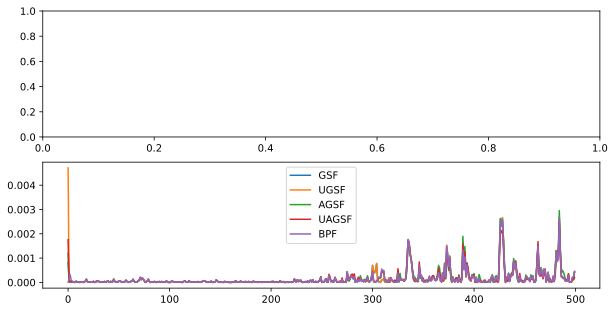

sim 2/10
key0:  [4038682467 4049047219]
key:  [1123993949 1633776119]
       Time taken for GSF:  0.8426849842071533
       Time taken for UGSF:  1.295809030532837
       Time taken for AGSF:  2.876149892807007
       Time taken for UAGSF:  4.2645649909973145
       Time taken for BPF:  5.141955137252808
              GSF RMSE: nan
              UGSF RMSE: 0.011994869
              AGSF RMSE: 0.009842679
              UAGSF RMSE: 0.011701761
              BPF RMSE: 0.009765926


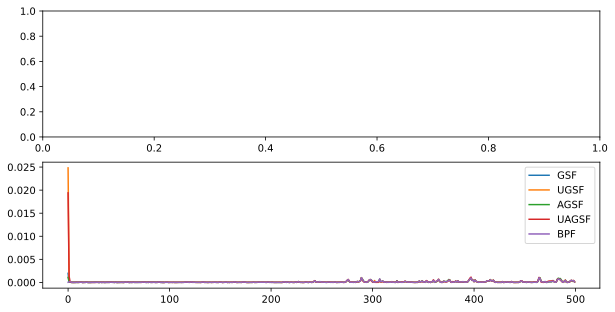

sim 3/10
key0:  [3295730785 1907469606]
key:  [2175656443 3507338041]
       Time taken for GSF:  0.7646219730377197
       Time taken for UGSF:  1.4134490489959717
       Time taken for AGSF:  2.8719680309295654
       Time taken for UAGSF:  4.209389925003052
       Time taken for BPF:  5.273721933364868
              GSF RMSE: nan
              UGSF RMSE: 0.010779891
              AGSF RMSE: 0.00703976
              UAGSF RMSE: 0.009486782
              BPF RMSE: 0.006824839


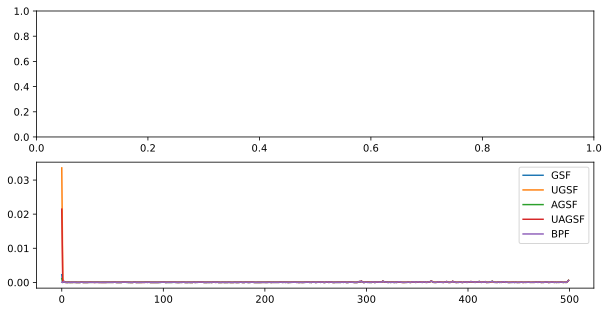

sim 4/10
key0:  [1795368326  584935165]
key:  [1120832370 3770592918]
       Time taken for GSF:  0.7613608837127686
       Time taken for UGSF:  1.2967500686645508
       Time taken for AGSF:  3.0018908977508545
       Time taken for UAGSF:  4.310298204421997
       Time taken for BPF:  5.0469419956207275
              GSF RMSE: 0.022512922
              UGSF RMSE: 0.022846533
              AGSF RMSE: 0.022587886
              UAGSF RMSE: 0.023281047
              BPF RMSE: 0.024145812


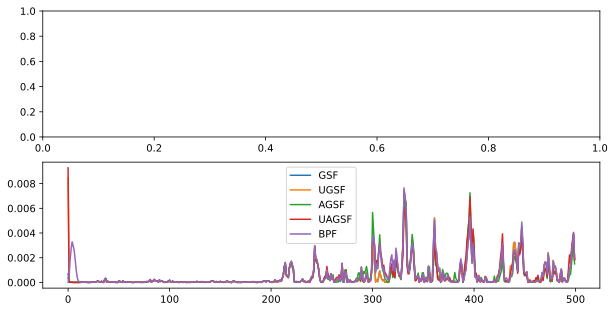

sim 5/10
key0:  [ 456292018 1165566599]
key:  [4102745572 3277364256]
       Time taken for GSF:  0.7635440826416016
       Time taken for UGSF:  1.4712638854980469
       Time taken for AGSF:  2.873445749282837
       Time taken for UAGSF:  4.279617786407471
       Time taken for BPF:  4.865453243255615
              GSF RMSE: 0.014385444
              UGSF RMSE: 0.0155005865
              AGSF RMSE: 0.013890668
              UAGSF RMSE: 0.014464718
              BPF RMSE: 0.023265244


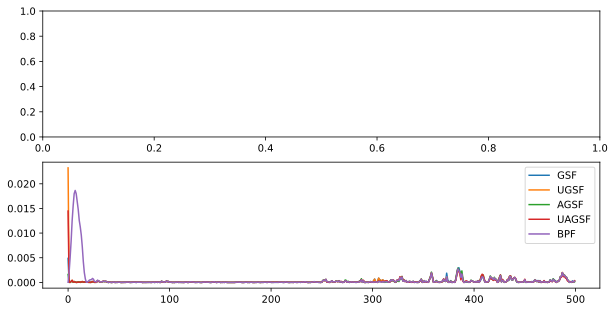

sim 6/10
key0:  [212254551 972031800]
key:  [4176427977  237722671]
       Time taken for GSF:  0.7674410343170166
       Time taken for UGSF:  1.304596185684204
       Time taken for AGSF:  2.9071199893951416
       Time taken for UAGSF:  4.361572742462158
       Time taken for BPF:  5.2254250049591064
              GSF RMSE: nan
              UGSF RMSE: 0.009049686
              AGSF RMSE: 0.00472371
              UAGSF RMSE: 0.0071466714
              BPF RMSE: 0.004344754


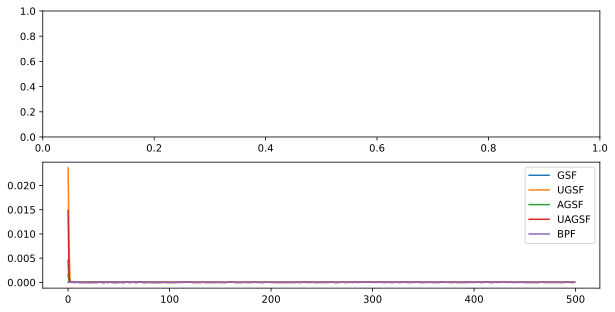

sim 7/10
key0:  [3685475569 1761638195]
key:  [1802191850  425137017]
       Time taken for GSF:  0.9977290630340576
       Time taken for UGSF:  1.310837984085083
       Time taken for AGSF:  2.94472599029541
       Time taken for UAGSF:  4.117202043533325
       Time taken for BPF:  5.407542943954468
              GSF RMSE: nan
              UGSF RMSE: 0.010381418
              AGSF RMSE: 0.010141604
              UAGSF RMSE: 0.010449318
              BPF RMSE: 0.00951728


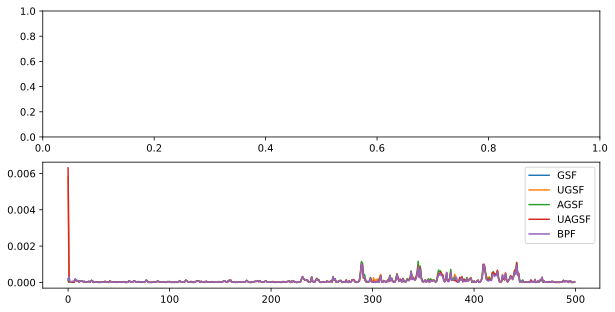

sim 8/10
key0:  [2004312237 1080707979]
key:  [3564672657 2387443400]
       Time taken for GSF:  0.7633967399597168
       Time taken for UGSF:  1.3054289817810059
       Time taken for AGSF:  2.9757771492004395
       Time taken for UAGSF:  4.360138893127441
       Time taken for BPF:  5.152336835861206
              GSF RMSE: nan
              UGSF RMSE: 0.017502185
              AGSF RMSE: 0.017557133
              UAGSF RMSE: 0.018166617
              BPF RMSE: 0.017826246


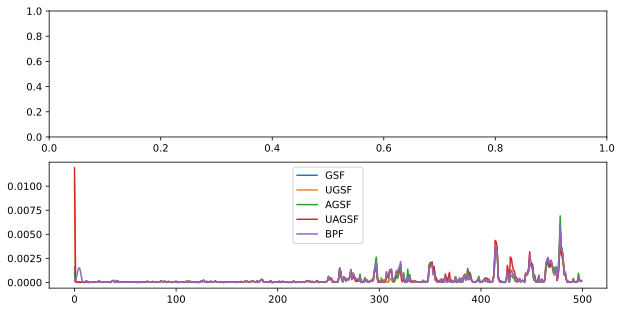

sim 9/10
key0:  [2372184986  857659058]
key:  [2470550142  587965772]
       Time taken for GSF:  0.7723560333251953
       Time taken for UGSF:  1.3079290390014648
       Time taken for AGSF:  2.9954917430877686
       Time taken for UAGSF:  4.249597787857056
       Time taken for BPF:  5.437355041503906
              GSF RMSE: 0.018159844
              UGSF RMSE: 0.021792458
              AGSF RMSE: 0.018488424
              UAGSF RMSE: 0.021928536
              BPF RMSE: 0.016845297


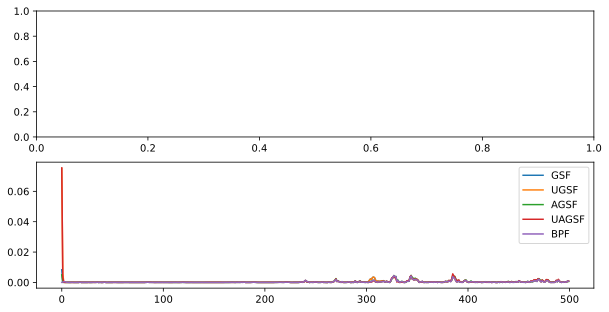

sim 10/10
key0:  [1353098956 1641448171]
key:  [ 605080484 2204356190]
       Time taken for GSF:  0.782850980758667
       Time taken for UGSF:  1.2902851104736328
       Time taken for AGSF:  3.054111957550049
       Time taken for UAGSF:  4.084794998168945
       Time taken for BPF:  5.227934837341309
              GSF RMSE: nan
              UGSF RMSE: 0.007128872
              AGSF RMSE: 0.0054908805
              UAGSF RMSE: 0.007855734
              BPF RMSE: 0.007988659


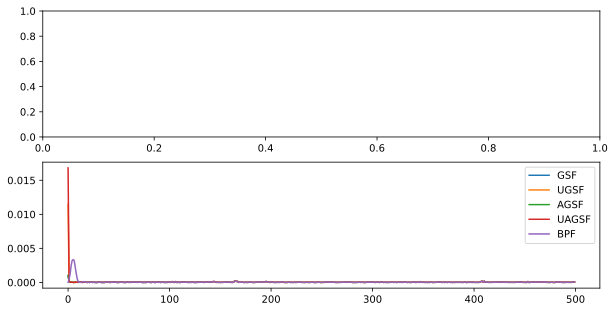

In [6]:
verbose = False
Nsim = 10
gsf_rmse = jnp.zeros(Nsim)
ugsf_rmse = jnp.zeros(Nsim)
agsf_rmse = jnp.zeros(Nsim)
uagsf_rmse = jnp.zeros(Nsim)
bpf_rmse = jnp.zeros(Nsim)

gsf_norm = jnp.zeros((Nsim, seq_length))
ugsf_norm = jnp.zeros((Nsim, seq_length))
agsf_norm = jnp.zeros((Nsim, seq_length))
uagsf_norm = jnp.zeros((Nsim, seq_length))
bpf_norm = jnp.zeros((Nsim, seq_length))

gsf_time = jnp.zeros(Nsim)
ugsf_time = jnp.zeros(Nsim)
agsf_time = jnp.zeros(Nsim)
uagsf_time = jnp.zeros(Nsim)
bpf_time = jnp.zeros(Nsim)
next_key = jr.PRNGKey(0)
for i in range(Nsim):
    print('sim {}/{}'.format(i+1, Nsim))
    # Generate Data
    key0, key, next_key = jr.split(next_key, 3)
    print('key0: ', key0)
    print('key: ', key)
    states, emissions = model.sample(params, key0, seq_length, inputs = inputs)

    # GSF
    M = 100
    tin = time.time()
    posterior_filtered_gsf = gf.gaussian_sum_filter(params, emissions, M, 1, inputs)
    point_estimate_gsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_gsf.means, posterior_filtered_gsf.weights), axis=0)
    tout = time.time()
    t_gsf= tout - tin
    print('       Time taken for GSF: ', tout - tin)

    # U-GSF
    tin = time.time()
    uparams = ParamsUKF(1,0,0)
    posterior_filtered_ugsf = gf.unscented_gaussian_sum_filter(params, uparams, emissions, M, 1, inputs)
    point_estimate_ugsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_ugsf.means, posterior_filtered_ugsf.weights), axis=0)
    tout = time.time()
    t_ugsf= tout - tin
    print('       Time taken for UGSF: ', tout - tin)

    # AGSF
    opt_args = (0.9, 0.9)
    num_components = [100, 5, 5]
    tin = time.time()
    posterior_filtered_agsf, aux_outputs = gf.speedy_augmented_gaussian_sum_filter(params, emissions, num_components, rng_key = key, opt_args = opt_args, inputs=inputs)    
    point_estimate_agsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_agsf.means, posterior_filtered_agsf.weights), axis=0)
    tout = time.time()
    t_agsf= tout - tin
    print('       Time taken for AGSF: ', tout - tin)

    # U-AGSF
    tin = time.time()
    # posterior_filtered_uagsf, aux_outputs = gf.unscented_agsf(params, uparams, emissions, num_components, rng_key = key, opt_args = opt_args, inputs=inputs)
    posterior_filtered_uagsf, aux_outputs = gf.speedy_unscented_agsf(params, uparams, emissions, num_components, key, opt_args, inputs=inputs)
    point_estimate_uagsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_uagsf.means, posterior_filtered_uagsf.weights), axis=0)
    tout = time.time()
    t_uagsf= tout - tin
    print('       Time taken for UAGSF: ', tout - tin)

    # BPF
    tin = time.time()
    num_particles = 100000

    params_bpf = ParamsBPF(
        initial_mean=mu0,
        initial_covariance=Sigma0,
        dynamics_function=f,
        dynamics_noise_bias=q0,
        dynamics_noise_covariance=Q,
        emission_function=g,
        emission_noise_bias=r0,
        emission_noise_covariance=R,
        emission_distribution_log_prob = glp
    )

    posterior_bpf = gf.bootstrap_particle_filter(params_bpf, emissions, num_particles, key, inputs, 1.0)
    point_estimate_bpf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_bpf["particles"], posterior_bpf["weights"]), axis=0)
    tout = time.time()
    t_bpf = tout - tin
    print('       Time taken for BPF: ', tout - tin)

    # Computation of errors
    gsf_rmse = gsf_rmse.at[i].set(utils.rmse(point_estimate_gsf[:, (0,2)], states[:, (0,2)]))
    ugsf_rmse = ugsf_rmse.at[i].set(utils.rmse(point_estimate_ugsf[:, (0,2)], states[:, (0,2)]))
    agsf_rmse = agsf_rmse.at[i].set(utils.rmse(point_estimate_agsf[:, (0,2)], states[:, (0,2)]))
    uagsf_rmse = uagsf_rmse.at[i].set(utils.rmse(point_estimate_uagsf[:, (0,2)], states[:, (0,2)]))
    bpf_rmse = bpf_rmse.at[i].set(utils.rmse(point_estimate_bpf[:, (0,2)], states[:, (0,2)]))

    print('              GSF RMSE:', gsf_rmse[i])                                                                           
    print('              UGSF RMSE:', ugsf_rmse[i])
    print('              AGSF RMSE:', agsf_rmse[i])
    print('              UAGSF RMSE:', uagsf_rmse[i])
    print('              BPF RMSE:', bpf_rmse[i])

    gsf_norm = gsf_norm.at[i].set(jnp.linalg.norm(point_estimate_gsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    ugsf_norm = ugsf_norm.at[i].set(jnp.linalg.norm(point_estimate_ugsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    agsf_norm = agsf_norm.at[i].set(jnp.linalg.norm(point_estimate_agsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    uagsf_norm = uagsf_norm.at[i].set(jnp.linalg.norm(point_estimate_uagsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    bpf_norm = bpf_norm.at[i].set(jnp.linalg.norm(point_estimate_bpf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)

    fig, axes = plt.subplots(2, 1, figsize=(10, 5))
    # axes[0].plot(states[:,0], label='True')
    # axes[0].plot(point_estimate_gsf[:,0], label='GSF')
    # axes[0].plot(point_estimate_ugsf[:,0], label='UGSF')
    # axes[0].plot(point_estimate_agsf[:,0], label='AGSF')
    # axes[0].plot(point_estimate_uagsf[:,0], label='UAGSF')
    # axes[0].plot(point_estimate_bpf[:,0], label='BPF')
    # axes[0].plot(emissions[:,0], label='Observed')
    # axes[0].legend()

    axes[1].plot(jnp.linalg.norm(point_estimate_gsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].plot(jnp.linalg.norm(point_estimate_ugsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].plot(jnp.linalg.norm(point_estimate_agsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].plot(jnp.linalg.norm(point_estimate_uagsf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].plot(jnp.linalg.norm(point_estimate_bpf[:,(0,2)] - states[:,(0,2)], axis = 1)**2)
    axes[1].legend(['GSF', 'UGSF', 'AGSF', 'UAGSF', 'BPF'])

    plt.show()


In [7]:
gsf_avg_norm = gsf_norm.sum(axis=0)/Nsim
ugsf_avg_norm = ugsf_norm.sum(axis=0)/Nsim
agsf_avg_norm = agsf_norm.sum(axis=0)/Nsim
uagsf_avg_norm = uagsf_norm.sum(axis=0)/Nsim
bpf_avg_norm = bpf_norm.sum(axis=0)/Nsim

In [8]:
jnp.sum(gsf_avg_norm), jnp.sum(ugsf_avg_norm), jnp.sum(agsf_avg_norm), jnp.sum(uagsf_avg_norm), jnp.sum(bpf_avg_norm)

(Array(nan, dtype=float32),
 Array(0.11035731, dtype=float32),
 Array(0.09091523, dtype=float32),
 Array(0.10815571, dtype=float32),
 Array(0.10970162, dtype=float32))

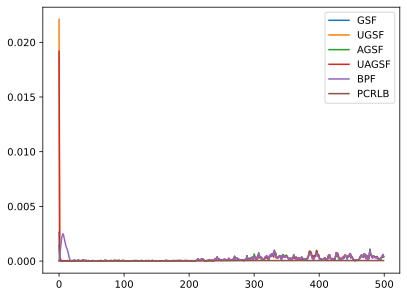

In [9]:
plt.plot(gsf_avg_norm, label='GSF')
plt.plot(ugsf_avg_norm, label='UGSF')
plt.plot(agsf_avg_norm, label='AGSF')
plt.plot(uagsf_avg_norm, label='UAGSF')
plt.plot(bpf_avg_norm, label='BPF')
plt.plot(CRLB[:,0,0], label='PCRLB')
plt.legend()
plt.show()